In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data

In [ ]:
def mostrar(imagens, titulos, cmap="gray", tamanho=4):

  n = len(imagens)
  plt.figure(figsize=(tamanho*n, tamanho))

  for i in range(n):
    plt.subplot(1,n,i+1)
    plt.imshow(imagens[i], cmap=cmap)
    plt.title(titulos[i])
    plt.axis("off")
  plt.show()

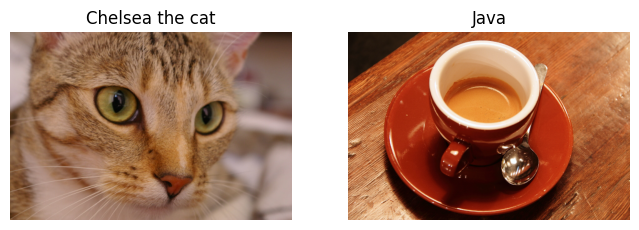

In [ ]:
gato = data.cat()
cafe = data.coffee()

mostrar([gato, cafe], ["Chelsea the cat", "Java"])


array([[ 47, 123, 133, ...,  14,   3,  12],
       [ 93, 144, 145, ...,  12,   7,   7],
       [126, 147, 143, ...,   2,  13,   3],
       ...,
       [ 81,  79,  74, ...,   6,   4,   7],
       [ 88,  82,  74, ...,   5,   7,   8],
       [ 91,  79,  68, ...,   4,  10,   7]], shape=(303, 384), dtype=uint8)
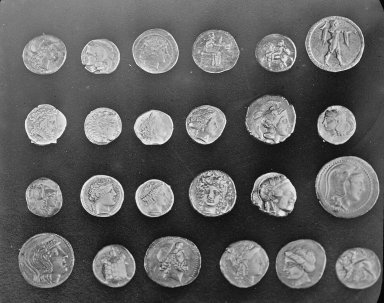

In [ ]:
moedas = data.coins()

moedas

array([[116, 123, 135, ...,  14,   9,   8],
       [122, 128, 137, ...,  16,   9,   8],
       [131, 134, 139, ...,  21,  11,   9],
       ...,
       [ 81,  79,  74, ...,   7,   6,   6],
       [ 82,  79,  74, ...,   7,   7,   7],
       [ 82,  80,  74, ...,   7,   7,   7]], shape=(303, 384), dtype=uint8)
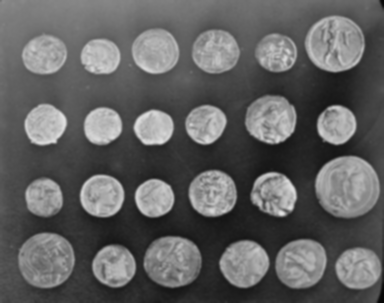

In [ ]:
moedas_suave = cv2.GaussianBlur(moedas, (5,5), 0)

moedas_suave

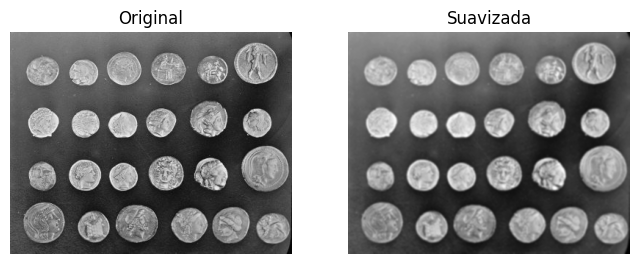

In [ ]:
mostrar([moedas, moedas_suave], ["Original", "Suavizada"])

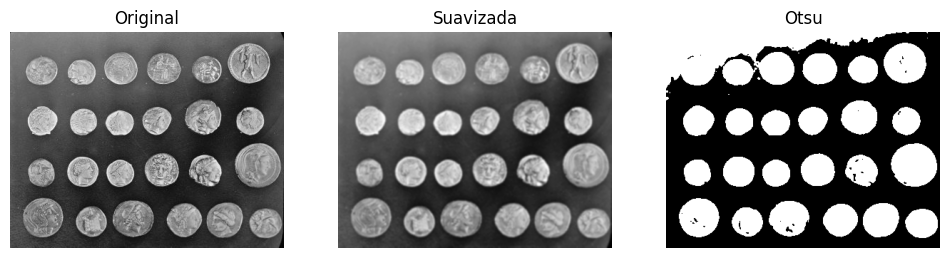

In [ ]:
moedas_otsu = cv2.threshold(moedas_suave, 0, 255, cv2.THRESH_OTSU)[1]

mostrar([moedas, moedas_suave, moedas_otsu], ["Original", "Suavizada", "Otsu"])

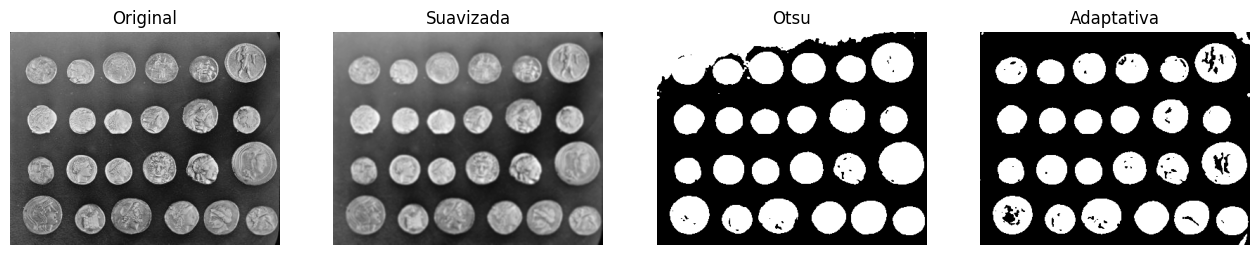

In [ ]:
moedas_adapt = cv2.adaptiveThreshold(moedas_suave, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 101, -10)

mostrar([moedas, moedas_suave, moedas_otsu, moedas_adapt], ["Original", "Suavizada", "Otsu", "Adaptativa"])

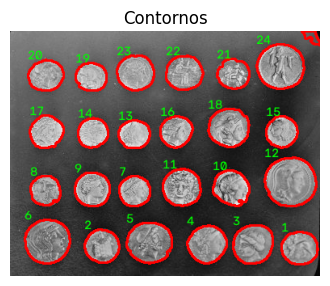

In [ ]:
contornos = cv2.findContours(moedas_adapt, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0]

contornos = [c for c in contornos if cv2.contourArea(c) >=100]

moedas_contornos = cv2.cvtColor(moedas, cv2.COLOR_GRAY2BGR)

cv2.drawContours(moedas_contornos, contornos, -1, (255,0,0), 2)

for i,c in enumerate(contornos):

  x, y, w, h = cv2.boundingRect(c)
  cv2.putText(
      moedas_contornos,
      str(i+1),
      (x,y),
      cv2.FONT_HERSHEY_SIMPLEX,
      0.5,
      (0,255,0)
  )

mostrar([moedas_contornos], ["Contornos"])